# RANGOT — Treinamento e comparação científica

IA · FACOM/UFMS · 2026/2 · Prof. Bruno M. Nogueira

Grupo CGJ · Restaurante Universitário UFMS.

Missão 08: dois classificadores, treino/CV, comparação 3 algoritmos × 2 representações e pipelines serializáveis. Todas as saídas devem ser obtidas por execução real. Este notebook não executa a avaliação final, OpenRouter, A1 ou seleção de limiar.


## 0. Ambiente

Execute a partir da raiz com o ambiente de `requirements.txt`. O kernel `rangot` deve apontar para esse mesmo Python. Não há instalação automática, clonagem, rede ou leitura de credenciais. Em um terminal autorizado, prepare as dependências e registre o kernel conforme `docs/EXPERIMENTOS_CLASSIFICADORES.md`.


In [1]:
import os
import sys
import json
import hashlib
from pathlib import Path

raiz = Path.cwd()
if not (raiz / "chatbot").is_dir():
    if raiz.name == "notebooks" and (raiz.parent / "chatbot").is_dir():
        raiz = raiz.parent
    else:
        raise RuntimeError("Execute a partir da raiz do RANGOT ou de notebooks/.")
os.chdir(raiz)
sys.path.insert(0, str(raiz))
os.environ["MPLCONFIGDIR"] = str(raiz / ".cache/matplotlib")
HASHES = {
    "dados/treino.csv": "fc260493bf144e3a6b5ecac2e2e7064f31b53dda597948cfc8e689fea5b665f5",
    "dados/teste.csv": "fa760e167d565a9a3e5bd015465c4ec945f7855e0bd78b5542dc561e21ea9b81",
}
for nome, esperado in HASHES.items():
    assert hashlib.sha256((raiz / nome).read_bytes()).hexdigest() == esperado, nome
print("Python:", sys.version.split()[0])
print("Hashes íntegros; o teste foi consultado somente como bytes para SHA-256.")


Python: 3.12.13
Hashes íntegros; o teste foi consultado somente como bytes para SHA-256.


In [2]:
import numpy as np
import pandas as pd
from IPython.display import display, SVG
from chatbot.experimentos import (
    preparar, conjuntos_estagios, candidato, experimentar_estagio, finalizar,
    conferir_integridade, ALGORITMOS, REPRESENTACOES, SEED, FOLDS, LIMITACOES,
)
from chatbot.config import carregar_config
from chatbot.modelos import carregar_classificadores
from chatbot.rotulos import CLASSES_ESCOPO
from importlib.metadata import version

print({p: version(p) for p in ("numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "joblib")})
print("Seed:", SEED, "| folds:", FOLDS, "| jobs: 1; BLAS limitado a 1 thread durante ajuste")


{'numpy': '2.5.5', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'joblib': '1.6.0'}
Seed: 42 | folds: 5 | jobs: 1; BLAS limitado a 1 thread durante ajuste


## 1. Configuração

Intenções e contratos são carregados do YAML oficial. As rotas são decididas pelos classificadores. Não há mudança de configuração ou respostas fixas neste notebook.


In [3]:
config = carregar_config(raiz / "grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
display(pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intencao", "descricao"]))


Grupo: CGJ | Tema: Restaurante universitário


,intencao,descricao
0,cardapio,cardápio do dia ou da semana
1,horarios,horários de funcionamento
2,valores,preços das refeições e isenções
3,recarga_creditos,recarga de créditos e formas de pagamento
4,cadastro,cadastro e acesso ao RU
5,regras_uso,regras de uso do RU


## 2. Dados e independência do teste

O treino tem 550 exemplos: 50 por intenção RU, 100 chitchat e 150 fora_dominio; 268 humanos e 282 LLM (48,73% humanos). A curadoria utilizou 67 envios humanos agrupados por envio, base sintética anterior e complementos. O teste congelado tem 160 humanos conforme manifesto da curadoria; sua composição não é recalculada aqui e seus textos/rótulos não são carregados.

O responsável confirmou a conferência e aceitação das 124 frases da 07E. A seleção final 07G foi assistida por IA; a autoria manual dessa seleção não é presumida. Metadados da geração das cinco candidatas 07G ainda precisam ser recuperados. Fontes, prompts efetivamente disponíveis e decisões estão em `dados/prompts_llm.md`, `USO_DE_IA.md` e no protocolo.

A separação por envio e deduplicação entre conjuntos foram verificadas na curadoria. Esta missão verifica apenas o hash do teste. Dados originais não são alterados. `carregar_dados` remove espaços externos em memória, conforme interface existente.


In [4]:
config, treino, hashes_iniciais = preparar(raiz)
estagios = conjuntos_estagios(treino)
display(pd.crosstab(treino["intencao"], treino["origem"], margins=True))
print("Treino:", len(treino), "| tema:", len(estagios["tema"]))
print("Proporção humana:", treino["origem"].isin(["humano", "coletado"]).mean())


origem,humano,llm,All
intencao,,,
cadastro,26,24,50
cardapio,40,10,50
chitchat,25,75,100
fora_dominio,53,97,150
horarios,34,16,50
recarga_creditos,32,18,50
regras_uso,26,24,50
valores,32,18,50
All,268,282,550


Treino: 550 | tema: 300
Proporção humana: 0.48727272727272725


In [5]:
descritivo = treino.assign(caracteres=treino["texto"].str.len(), palavras=treino["texto"].str.split().str.len())
display(descritivo.groupby(["intencao", "origem"])[["caracteres", "palavras"]].agg(["count", "median", "mean"]).round(2))


caracteres               palavras              
                             count median   mean    count median   mean
intencao         origem                                                
cadastro         humano         26   53.5  55.31       26   10.5  10.27
                 llm            24   39.5  47.62       24    9.0   9.33
cardapio         humano         40   28.0  34.70       40    6.0   7.20
                 llm            10   30.0  31.00       10    6.5   6.90
chitchat         humano         25   31.0  31.68       25    6.0   5.76
                 llm            75   31.0  28.23       75    5.0   4.93
fora_dominio     humano         53   53.0  59.26       53   10.0  11.13
                 llm            97   70.0  60.61       97   11.0  10.02
horarios         humano         34   42.5  46.85       34   10.0   9.82
                 llm            16   27.0  28.31       16    6.5   6.56
recarga_creditos humano         32   50.0  59.25       32   10.5  11.50
                 llm            18   33.0  37.11       18    7.0   7.94
regras_uso       humano         26   44.5  51.12       26    8.5   9.73
                 llm            24   36.5  47.50       24    8.0   9.17
valores          humano         32   36.0  44.88       32    8.5   8.69
                 llm            18   27.0  27.72       18    6.0   6.22

## 3. Representações, algoritmos e protocolo

Comparamos TF-IDF de palavras (1,2) e caracteres internos à palavra `char_wb` (2,5), com `chatbot.texto.normalizar`, `min_df=1`, TF sublinear e sem remover stopwords. Negação e palavras interrogativas podem ser relevantes.

Algoritmos: regressão logística (probabilidades por escores lineares e perda logística regularizada) e SVM linear (separadores de margem, calibrados para obter probabilidades), ambas com pesos de classe balanceados. Complement Naive Bayes usa frequências no complemento das classes sob aproximação de independência entre características e suavização alpha; aceita TF-IDF esparso não negativo e é útil em classes desbalanceadas. Grades pequenas: C ∈ {0,1; 1; 10} para logística/SVM e alpha ∈ {0,1; 0,5; 1} para NB. As representações são mantidas fixas para permitir uma comparação clara com custo limitado.

Para cada estágio são as mesmas cinco folds estratificadas, embaralhadas com seed 42, para os seis candidatos. GridSearchCV mede F1 macro e acurácia. Seleção por maior F1 macro; desempate por acurácia, menor desvio e ordem estável. Desvio populacional (ddof=0), como nos resultados do GridSearchCV. As curvas são os três pontos da grade unidimensional: sem refazer ajustes redundantes.

**Calibração SVM:** sigmoid com três folds internas. `CalibratedClassifierCV` envolve TODO o pipeline TF-IDF + LinearSVC dentro do pipeline externo. Vocabulário/IDF e calibrador não veem a fold externa; nem a vetorização vê a validação interna do calibrador. `ensemble=False` permite refit do estimador em todos os dados de treinamento pertinentes.

**Limitações científicas:** CV usada para escolher candidatos e hiperparâmetros; os escores da busca e o diagnóstico OOF do escolhido são pós-seleção, possuem viés e não são estimativa independente. Não há CV aninhada. Famílias sintéticas, autores e perguntas humanas equivalentes podem atravessar folds estratificadas, apesar da independência entre treino e teste. Isso pode inflar CV. A análise por origem é descritiva, confundida por classe, estilo, dificuldade e concentração de famílias; não constitui o aprofundamento A3.


In [6]:
for algoritmo in ALGORITMOS:
    for representacao in REPRESENTACOES:
        pipeline, grade = candidato(algoritmo, representacao)
        print(algoritmo, representacao, grade)
print(LIMITACOES)


logistica palavras {'classificador__C': [0.1, 1.0, 10.0]}
logistica caracteres {'classificador__C': [0.1, 1.0, 10.0]}
complement_nb palavras {'classificador__alpha': [0.1, 0.5, 1.0]}
complement_nb caracteres {'classificador__alpha': [0.1, 0.5, 1.0]}
svm_calibrada palavras {'calibrado__estimator__classificador__C': [0.1, 1.0, 10.0]}
svm_calibrada caracteres {'calibrado__estimator__classificador__C': [0.1, 1.0, 10.0]}
CV interna usada para escolher algoritmos/representacoes/hiperparametros. Medias da busca e OOF do vencedor possuem vies de selecao: nao sao estimativa independente ou teste final. Nao foi realizada CV aninhada. Familias de parafrases e autores podem atravessar folds estratificadas; nao houve agrupamento por familia/autoria, o que pode elevar os resultados. Comparacoes por origem sao descritivas, sem controle causal de classe, estilo ou dificuldade. As probabilidades OOF nao definem limiar nesta missao; A1 e limiar ficam para a Missao 09.


## 4. Classificador de escopo

`rotulo_escopo`/`adicionar_escopo` oficiais derivam dominio das seis intenções. Treinamos com as 550 mensagens. Nenhuma previsão de outro modelo redefine os rótulos.


In [7]:
escopo = experimentar_estagio("escopo", estagios["escopo"], CLASSES_ESCOPO)
display(escopo["comparacao"].round(5))
display(escopo["folds"].round(5))
print("Seleção:", escopo["vencedor"])


,etapa,algoritmo,representacao,f1_macro_media,f1_macro_desvio,accuracy_media,accuracy_desvio,parametros,segundos_busca
0,escopo,svm_calibrada,caracteres,0.92287,0.01330,0.93091,0.01477,"{""calibrado__estimator__classificador__C"": 1.0}",1.66421
1,escopo,logistica,caracteres,0.91501,0.01726,0.92364,0.01585,"{""classificador__C"": 10.0}",0.78823
2,escopo,svm_calibrada,palavras,0.89773,0.01924,0.90545,0.01958,"{""calibrado__estimator__classificador__C"": 10.0}",0.48864
3,escopo,logistica,palavras,0.86643,0.03564,0.88545,0.02852,"{""classificador__C"": 10.0}",0.31459
4,escopo,complement_nb,palavras,0.84905,0.04579,0.86727,0.04170,"{""classificador__alpha"": 0.1}",0.17115
5,escopo,complement_nb,caracteres,0.84861,0.02060,0.86545,0.01941,"{""classificador__alpha"": 0.1}",0.52048


,etapa,fold,n_validacao,f1_macro,accuracy
0,escopo,1,110,0.93844,0.95455
1,escopo,2,110,0.93580,0.93636
2,escopo,3,110,0.92249,0.92727
3,escopo,4,110,0.91508,0.92727
4,escopo,5,110,0.90252,0.90909


Seleção: {'etapa': 'escopo', 'algoritmo': 'svm_calibrada', 'representacao': 'caracteres', 'f1_macro_media': 0.9228672897685202, 'f1_macro_desvio': 0.013299606798230144, 'accuracy_media': 0.9309090909090909, 'accuracy_desvio': 0.014770978917519955, 'parametros': '{"calibrado__estimator__classificador__C": 1.0}', 'segundos_busca': 1.6642105409991927}


In [8]:
display(escopo["matriz"].pivot(index="real", columns="predito", values="quantidade").reindex(index=CLASSES_ESCOPO, columns=CLASSES_ESCOPO))
print("OOF pós-seleção (agrupado; diferente da média simples das folds):", escopo["extras"])
display(escopo["origem"].round(5))
display(escopo["classes"].round(5))


predito,dominio,chitchat,fora_dominio
real,,,
dominio,285,6,9
chitchat,6,90,4
fora_dominio,11,2,137


OOF pós-seleção (agrupado; diferente da média simples das folds): {'f1_macro_oof_agrupado': 0.9230893654149468, 'accuracy_oof_agrupada': 0.9309090909090909, 'n': 550, 'erros': 38, 'falsos_aceites': 17, 'falsas_recusas': 15, 'n_nao_dominio': 250, 'n_dominio': 300, 'taxa_falso_aceite': 0.068, 'taxa_falsa_recusa': 0.05}


,etapa,origem,n,f1_macro,accuracy
0,escopo,humano,268,0.92713,0.94403
1,escopo,llm,282,0.91677,0.91844


,etapa,classe,precision,recall,f1,suporte
0,escopo,dominio,0.94371,0.95000,0.94684,300
1,escopo,chitchat,0.91837,0.90000,0.90909,100
2,escopo,fora_dominio,0.91333,0.91333,0.91333,150


### Erros de escopo: inspeção qualitativa

Os exemplos abaixo vêm somente do treino e são os primeiros erros em ordem estável de registro, sem seleção pelo teste. Falso aceite é não-domínio aceito como domínio (denominador: todos os não-domínio); falsa recusa é domínio rejeitado (denominador: todos os domínio). No RU, aceitar uma pergunta de outro serviço pode gerar resposta indevida; recusar uma solicitação legítima reduz cobertura. Não interpretar métricas como garantia operacional.


In [9]:
erros_escopo = escopo["oof"].query("real != predito").merge(treino[["linha_treino", "texto"]], on="linha_treino", validate="one_to_one")
display(erros_escopo[["linha_treino", "texto", "real", "predito", "origem", "confianca"]].head(10))
diag = escopo["oof"].assign(erro=lambda d: d["real"].ne(d["predito"])).merge(descritivo[["linha_treino", "caracteres"]], on="linha_treino", validate="one_to_one")
display(diag.groupby(["origem", "erro"])["caracteres"].agg(["count", "median"]))


,linha_treino,texto,real,predito,origem,confianca
0,6,Tem doce hoje?,dominio,chitchat,humano,0.635088
1,28,Qual a mistura hj ?,dominio,chitchat,humano,0.596632
2,29,Tem bife a parmegiana ?,dominio,fora_dominio,humano,0.636221
3,92,Qnt e isso? Tenho direito a isencao?,dominio,chitchat,humano,0.749265
4,100,Qual o valor da refeição para estudantes de gr...,dominio,fora_dominio,humano,0.828112
5,139,Aoba se eu pagar o ru no pix e o banco der err...,dominio,fora_dominio,humano,0.638772
6,143,Da pra fzr recarga digital?,dominio,fora_dominio,humano,0.776677
7,188,É difícil fazer essa carteirinha?,dominio,chitchat,humano,0.639013
8,195,Preciso de algum documento pra me cadastrar? T...,dominio,fora_dominio,humano,0.598523
9,247,Quanto é a bolsa pra quem é baixa renda e qual...,fora_dominio,dominio,humano,0.687235


count  median
origem erro                
humano False    253    41.0
       True      15    36.0
llm    False    259    36.0
       True      23    40.0

## 5. Classificador de tema

Somente os 300 exemplos com rótulo original de domínio entram neste estágio. Mesmas três famílias de algoritmos, duas representações, grades pequenas, cinco folds e critério do escopo. A matriz é tema-oráculo no treino; não é uma métrica ponta a ponta da cascata.


In [10]:
tema = experimentar_estagio("tema", estagios["tema"], config.nomes_intencoes)
display(tema["comparacao"].round(5))
display(tema["folds"].round(5))
print("Seleção:", tema["vencedor"])
display(tema["matriz"].pivot(index="real", columns="predito", values="quantidade").reindex(index=config.nomes_intencoes, columns=config.nomes_intencoes))
display(tema["origem"].round(5))
display(tema["classes"].round(5))


,etapa,algoritmo,representacao,f1_macro_media,f1_macro_desvio,accuracy_media,accuracy_desvio,parametros,segundos_busca
0,tema,svm_calibrada,caracteres,0.91996,0.02451,0.92000,0.02449,"{""calibrado__estimator__classificador__C"": 0.1}",1.03970
1,tema,logistica,caracteres,0.91954,0.01891,0.92000,0.01944,"{""classificador__C"": 10.0}",0.55147
2,tema,complement_nb,caracteres,0.90929,0.02208,0.91000,0.02261,"{""classificador__alpha"": 0.5}",0.29629
3,tema,complement_nb,palavras,0.89800,0.01336,0.90000,0.01491,"{""classificador__alpha"": 0.1}",0.13739
4,tema,svm_calibrada,palavras,0.88366,0.01832,0.88667,0.01633,"{""calibrado__estimator__classificador__C"": 10.0}",0.35789
5,tema,logistica,palavras,0.88067,0.02341,0.88333,0.02108,"{""classificador__C"": 10.0}",0.23906


,etapa,fold,n_validacao,f1_macro,accuracy
0,tema,1,60,0.96658,0.96667
1,tema,2,60,0.89904,0.90000
2,tema,3,60,0.91643,0.91667
3,tema,4,60,0.91704,0.91667
4,tema,5,60,0.90071,0.90000


Seleção: {'etapa': 'tema', 'algoritmo': 'svm_calibrada', 'representacao': 'caracteres', 'f1_macro_media': 0.9199591534831809, 'f1_macro_desvio': 0.024507628915550434, 'accuracy_media': 0.9199999999999999, 'accuracy_desvio': 0.02449489742783178, 'parametros': '{"calibrado__estimator__classificador__C": 0.1}', 'segundos_busca': 1.0397042080003303}


predito,cardapio,horarios,valores,recarga_creditos,cadastro,regras_uso
real,,,,,,
cardapio,46,1,1,0,1,1
horarios,3,46,1,0,0,0
valores,3,1,45,0,0,1
recarga_creditos,1,0,2,45,1,1
cadastro,0,0,1,2,46,1
regras_uso,1,0,1,0,0,48


,etapa,origem,n,f1_macro,accuracy
0,tema,humano,190,0.93995,0.93684
1,tema,llm,110,0.88463,0.89091


,etapa,classe,precision,recall,f1,suporte
0,tema,cardapio,0.85185,0.92,0.88462,50
1,tema,horarios,0.95833,0.92,0.93878,50
2,tema,valores,0.88235,0.90,0.89109,50
3,tema,recarga_creditos,0.95745,0.90,0.92784,50
4,tema,cadastro,0.95833,0.92,0.93878,50
5,tema,regras_uso,0.92308,0.96,0.94118,50


### Erros de tema e limites de interpretação

Inspecionar abaixo a finalidade do pedido e as palavras compartilhadas entre rótulos. Cartão pode indicar pagamento, cadastro ou conduta; perguntas de acesso e pedidos genéricos podem ser subespecificados. Essas são hipóteses para interpretar os erros efetivamente exibidos, não afirmações antecipadas sobre o vencedor ou seus resultados. Comparar erros humanos e LLM sem concluir causalidade; mensagens sintéticas podem ser mais regulares e próximas de famílias presentes no treino de outras folds. Não reabrir a curadoria nem ajustar modelos pelo teste.


In [11]:
erros_tema = tema["oof"].query("real != predito").merge(treino[["linha_treino", "texto"]], on="linha_treino", validate="one_to_one")
display(erros_tema[["linha_treino", "texto", "real", "predito", "origem", "confianca"]].head(10))
print("Diagnóstico agrupado pós-seleção:", tema["extras"])
display(tema["curvas"][["parametros", "mean_train_f1_macro", "mean_test_f1_macro", "std_test_f1_macro"]])


,linha_treino,texto,real,predito,origem,confianca
0,13,será que tu pode me informar se tem alguma com...,cardapio,regras_uso,humano,0.816074
1,21,perguntaria quais as proteínas,cardapio,horarios,humano,0.727427
2,30,"Sim, ""Olá, o que tem para comer no restaurant...",cardapio,valores,humano,0.606368
3,42,bom dia mostra o menu do ru de segunda ai,cardapio,cadastro,llm,0.512036
4,48,O ru é só dia de semana ou fim de semana tbm a...,horarios,cardapio,humano,0.495623
5,70,hj tem ru? to c fome kkkk / ru ta aberto hj? q...,horarios,cardapio,humano,0.491778
6,78,quando funciona essa giromba,horarios,valores,humano,0.542792
7,93,"meu querido, tem como informar os valores pra ...",valores,cardapio,humano,0.593014
8,96,Tem promoções de destaque do Ru,valores,regras_uso,humano,0.436097
9,108,20 reais dá pra comer no RU ?,valores,cardapio,humano,0.348470


Diagnóstico agrupado pós-seleção: {'f1_macro_oof_agrupado': 0.9203778393448444, 'accuracy_oof_agrupada': 0.92, 'n': 300, 'erros': 24}


,parametros,mean_train_f1_macro,mean_test_f1_macro,std_test_f1_macro
15,"{""calibrado__estimator__classificador__C"": 0.1}",0.993333,0.919959,0.024508
16,"{""calibrado__estimator__classificador__C"": 1.0}",1.000000,0.919589,0.026665
17,"{""calibrado__estimator__classificador__C"": 10.0}",1.000000,0.915927,0.017930


## 6. Limiar de confiança

Reservado à Missão 09, junto com A1 e integração. Nesta missão não se escolhe limiar, não se altera `grupo.yaml` e não se calibra pelo teste. As probabilidades OOF do vencedor serão exportadas com ordem explícita de classes e limitação de viés de seleção; qualquer protocolo posterior deverá considerar essa limitação.


In [12]:
print("Limiar não selecionado nesta missão; configuração preservada:", config.limiar_tema)


Limiar não selecionado nesta missão; configuração preservada: 0.0


## 7. Salvar os modelos finais e artefatos

Depois da comparação, os pipelines selecionados foram ajustados com todo o treino pertinente. `finalizar` utiliza `salvar_classificadores` oficial, recarrega os arquivos, confere classes, probabilidades e equivalência em textos fictícios. Salva tabelas, metadados e figuras derivadas de execuções reais. Se houver falha de dependências ou escrita, a célula deve falhar: nenhum número substituto é criado.


Matplotlib is building the font cache; this may take a moment.


{
  "round_trip": true,
  "ficticios": 2,
  "sha256_escopo": "cd33ffcb0cbdc2727e2fb7bdb3d12d2098d9d4961e5be028152832ff8134b12e",
  "sha256_tema": "a674cbc37d89aba7130d65361584b08411840eecb8224d003ac15d83580da8ce"
}
Versões: {'numpy': '2.5.5', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'joblib': '1.6.0', 'matplotlib': '3.11.2', 'threadpoolctl': '3.8.0'}


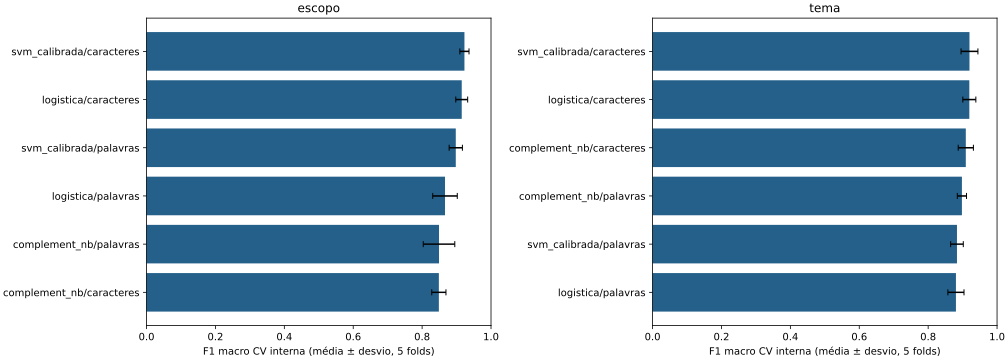

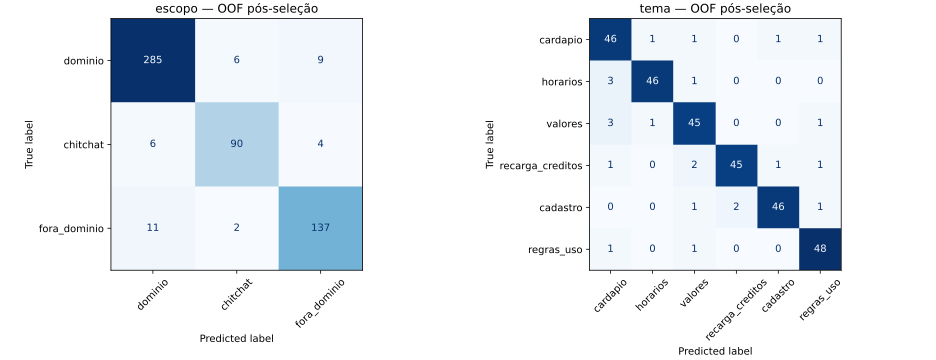

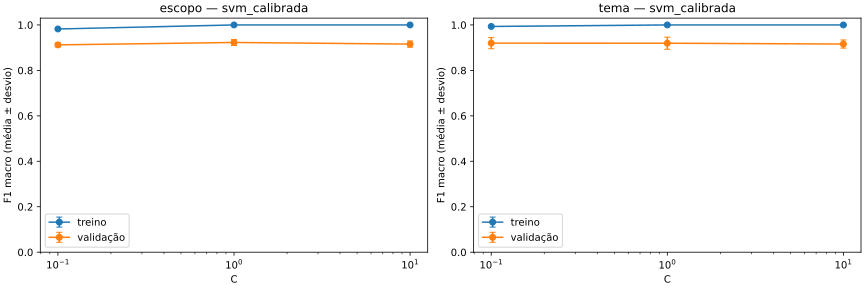

In [13]:
resultados = {"escopo": escopo, "tema": tema}
metadados = finalizar(raiz, config, treino, hashes_iniciais, resultados)
print(json.dumps(metadados["contratos_modelos"], indent=2))
print("Versões:", metadados["versoes"])
for nome in ("comparacao_cv", "matrizes_confusao", "curvas_validacao"):
    display(SVG(filename=str(raiz / "resultados/classificadores_08" / (nome + ".svg"))))


## 8. O chatbot funcionando — sanidade offline dos classificadores

Esta missão valida os modelos serializados com entradas fictícias. A integração do grafo, demonstração de respostas fixas e escolha de limiar ficam para a Missão 09. Não há importação de cliente LLM nem leitura de credenciais, cache RAG ou OpenRouter. As previsões abaixo verificam a interface, não qualidade semântica em dados científicos.


In [14]:
carregados = carregar_classificadores(config)
ficcao = ["EXEMPLO FICTÍCIO esfera orbital 73", "EXEMPLO FICTÍCIO prisma violeta 91"]
for nome, modelo in zip(("escopo", "tema"), carregados):
    print(nome, "classes:", list(modelo.classes_))
    print("predict fictício:", list(modelo.predict(ficcao)))
    print("predict_proba fictício:", modelo.predict_proba(ficcao))


escopo classes: [np.str_('chitchat'), np.str_('dominio'), np.str_('fora_dominio')]
predict fictício: [np.str_('chitchat'), np.str_('chitchat')]
predict_proba fictício: [[0.62740558 0.04012694 0.33246748]
 [0.56501886 0.01817349 0.41680765]]
tema classes: [np.str_('cadastro'), np.str_('cardapio'), np.str_('horarios'), np.str_('recarga_creditos'), np.str_('regras_uso'), np.str_('valores')]
predict fictício: [np.str_('recarga_creditos'), np.str_('regras_uso')]
predict_proba fictício: [[0.06642697 0.24938929 0.17665885 0.25048015 0.22106931 0.03597542]
 [0.10776983 0.0892837  0.05825837 0.09538665 0.54848389 0.10081756]]


## 9. Avaliação final no teste — não executada

Fica para autorização expressa após congelamento de modelos e limiar. Este notebook não contém chamada executável ao avaliador oficial, ao verificador ou leitura dos exemplos de teste. Os resultados desta missão são exclusivamente de treinamento/CV interna. C7 não pode ser inferido deles.


In [15]:
print("Avaliação final NÃO executada. Teste reservado e modelos sem seleção de limiar.")


Avaliação final NÃO executada. Teste reservado e modelos sem seleção de limiar.


## 10. Uso de IA generativa

Codex auxiliou no planejamento, escolha de candidatos/grades, código, testes, notebook e documentação. A conferência humana das 124 frases 07E foi confirmada pelo responsável nesta missão, preservando o histórico de curadoria por IA. Isso não se estende à nova selecionada 07G nem comprova revisão humana do código ou dos resultados.

A geração anterior 07D está documentada conforme registro fornecido (ChatGPT/GPT-6, sem OpenRouter); ferramenta/modelo/prompt da geração das cinco candidatas 07G permanecem pendentes. Os resultados devem ser métricas produzidas pelas bibliotecas em execução real, não números atribuídos à IA. Conferência científica pelo grupo, artigo e vídeo continuam necessários. Ver `USO_DE_IA.md`.


## 11. Verificação da entrega — integridade offline

Apenas integridade dos arquivos desta missão e contratos dos classificadores. O verificador oficial permanece reservado para a etapa final autorizada em cópia sem segredos. Não há execução dele neste notebook.

Para repetir a suíte offline: `python -B -m unittest discover -s tests`. Para repetir os experimentos sem executar o notebook: `python -B scripts/experimentar_classificadores.py`. As duas vias usam o mesmo módulo. Não executar ambas sem necessidade; as saídas reais deste notebook devem ser preservadas após Restart & Run All.


In [16]:
assert conferir_integridade(raiz, hashes_iniciais) == hashes_iniciais
print("Dados, configuração e três arquivos oficiais preservados.")
print("Treino:", len(treino), "| tema:", len(estagios["tema"]), "| nenhuma avaliação do teste.")
display(pd.DataFrame([{"etapa": etapa, **r["vencedor"]} for etapa, r in resultados.items()]))
print("Próxima missão: 09 — A1, limiar e integração. Nenhuma avaliação final nesta execução.")


Dados, configuração e três arquivos oficiais preservados.
Treino: 550 | tema: 300 | nenhuma avaliação do teste.


,etapa,algoritmo,representacao,f1_macro_media,f1_macro_desvio,accuracy_media,accuracy_desvio,parametros,segundos_busca
0,escopo,svm_calibrada,caracteres,0.922867,0.013300,0.930909,0.014771,"{""calibrado__estimator__classificador__C"": 1.0}",1.664211
1,tema,svm_calibrada,caracteres,0.919959,0.024508,0.920000,0.024495,"{""calibrado__estimator__classificador__C"": 0.1}",1.039704


Próxima missão: 09 — A1, limiar e integração. Nenhuma avaliação final nesta execução.


## 12. Missão 09 — A1 com folds comuns e referências preservadas

Comparamos cascata e modelo único de oito classes com SVM calibrada e TF-IDF de caracteres. Cinco folds externas estratificadas nas oito classes são idênticas para ambas. Em cada treino externo, C ∈ {0,1; 1; 10} é escolhido em três folds internas; a calibração envolve o pipeline inteiro em três folds próprias. O tema da cascata recebe somente os exemplos de domínio do treino externo. Nenhuma previsão de tema treinado em uma fold diferente é combinada com escopo.

Uma terceira linha, cascata_referencia_08, mantém os hiperparâmetros dos modelos 08 (C escopo=1; tema=0,1) para produzir as probabilidades OOF que correspondem à implantação. Os arquivos dos modelos e resultados 08 não são sobrescritos. Algoritmo/representação já foram escolhidos na 08 com este treino; autores/famílias podem atravessar folds, logo o estudo não é uma avaliação totalmente independente. O teste é apenas verificado por SHA-256.

As células 09 abaixo foram executadas em processo Python da mesma .venv com captura de saídas reais, sem reexecutar nem substituir as saídas 08. Também são executáveis num kernel Jupyter preparado. Reexecutar o aprofundamento não sobrescreve os modelos 08; a CLI --gravar exporta os resultados e o limiar quando houver escrita autorizada.


In [17]:
import io
import json
from pathlib import Path
import pandas as pd
from IPython.display import SVG, Markdown
from chatbot.aprofundamento import executar_memoria, referencias

raiz09 = Path.cwd()
resultado09 = executar_memoria(raiz09)
meta09 = resultado09["metadados"]
def tabela09(nome):
    return pd.read_csv(io.StringIO(resultado09["arquivos"][nome]))
print("A1 executado em cinco folds comuns; nenhuma leitura dos exemplos do teste.")
print("Melhor F1 médio numérico:", meta09["melhor_a1"])
print("Limiar selecionado exclusivamente no OOF de treinamento:", meta09["limiar_tema"])


A1 executado em cinco folds comuns; nenhuma leitura dos exemplos do teste.
Melhor F1 médio numérico: unico_cv_interna
Limiar selecionado exclusivamente no OOF de treinamento: 0.6


,arquitetura,f1_macro_media,f1_macro_desvio,accuracy_media,accuracy_desvio,f1_macro_oof,accuracy_oof,erros_oof,falsos_aceites_oof,falsas_recusas_oof,taxa_falso_aceite_oof,taxa_falsa_recusa_oof
0,cascata_cv_interna,0.882105,0.014006,0.889091,0.010602,0.882519,0.889091,61,20,13,0.080,0.043333
1,cascata_referencia_08,0.878718,0.009623,0.885455,0.009271,0.878652,0.885455,63,19,16,0.076,0.053333
2,unico_cv_interna,0.885115,0.018913,0.890909,0.019069,0.885421,0.890909,60,17,20,0.068,0.066667


,arquitetura,fold,f1_macro,accuracy,erros,falsos_aceites,falsas_recusas,taxa_falso_aceite,taxa_falsa_recusa
0,cascata_cv_interna,1,0.897698,0.900000,11,4,3,0.08,0.050000
1,unico_cv_interna,1,0.899794,0.900000,11,2,6,0.04,0.100000
2,cascata_referencia_08,1,0.889927,0.890909,12,3,6,0.06,0.100000
3,cascata_cv_interna,2,0.890102,0.900000,11,4,1,0.08,0.016667
4,unico_cv_interna,2,0.899115,0.909091,10,4,2,0.08,0.033333
5,cascata_referencia_08,2,0.890196,0.900000,11,4,1,0.08,0.016667
6,cascata_cv_interna,3,0.891103,0.890909,12,4,3,0.08,0.050000
7,unico_cv_interna,3,0.848441,0.854545,16,6,3,0.12,0.050000
8,cascata_referencia_08,3,0.866433,0.872727,14,4,3,0.08,0.050000
9,cascata_cv_interna,4,0.871371,0.881818,13,4,5,0.08,0.083333


,arquitetura,n_dominio,dominio_perdido_no_escopo,tema_correto_mas_bloqueado_pelo_escopo,dominio_passou_mas_tema_errou,n_nao_dominio,nao_dominio_encaminhado_ao_tema
0,cascata_cv_interna,300,13,11,22,250,20
1,cascata_referencia_08,300,16,14,22,250,19


,segundos_ajuste,ms_por_mensagem_batch,bytes_modelos_em_memoria
arquitetura,,,
cascata_cv_interna,1.245816,0.070402,609792.8
cascata_referencia_08,0.086152,0.070338,609792.8
unico_cv_interna,0.919549,0.036522,614408.4


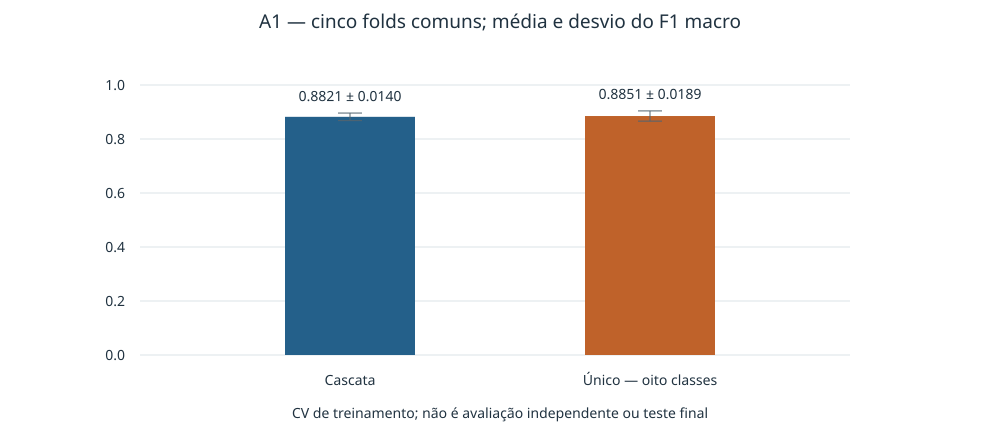

In [18]:
display(tabela09("a1_comparacao.csv"))
display(tabela09("a1_folds.csv"))
display(tabela09("a1_propagacao.csv"))
display(tabela09("a1_custos.csv").groupby("arquitetura")[["segundos_ajuste", "ms_por_mensagem_batch", "bytes_modelos_em_memoria"]].mean())
display(SVG(data=resultado09["arquivos"]["a1_comparacao.svg"]))


## 13. Limiar: critério declarado e limitações

Grade fixa de 18 valores entre 0 e 1. Política interna declarada antes da execução: custo 5 para resposta de domínio a não-domínio, 3 para intenção errada, 1 para esclarecimento, 2 para recusa indevida e 1 para troca social/fora. Minimizar custo total; empate por mais acertos diretos e menor limiar. Não são custos exigidos pelo professor nem validados com usuários.

A seleção utiliza a cascata 08 fixa em OOF comum de treinamento, incluindo falsos aceites do escopo. A sensibilidade considera também pesos (3,2) e (8,5) para os dois erros diretos, sem escolher pesos a partir dos resultados. Selecionar e descrever o limiar nos mesmos OOF traz otimismo. Esclarecimento não é acerto de intenção e pode reduzir acurácia/cobertura enquanto aumenta a precisão das respostas de domínio. O campo existente limiar_tema basta para integrar a política; nenhum limiar novo de escopo ou rota por LLM foi criado.


Critério: Minimizar custo OOF; desempate por mais acertos diretos e menor limiar. Custos declarados antes da execução.
Limitações: Familia/representacao escolhidas na 08 com este treino; CV interna adicional so para C nao remove todo vies de selecao anterior. Familias/autores podem atravessar folds. Limiar escolhido e descrito nos mesmos OOF: diagnostico otimista, sem estimativa independente de sua politica. Custos sao decisao interna, nao regra do professor. Tempos batch em amostra pequena e referencia com tempo de refit apenas adicional nao sao benchmark de producao.


,limiar,aceites_dominio,acertos_diretos,accuracy_aceites,esclarecimentos,esclarecimentos_dominio,esclarecimentos_nao_dominio,erros_diretos,erros_evitados,acertos_convertidos_esclarecimento,falsos_aceites,falsas_recusas,perda_total,perda_media,f1_macro,accuracy,erros,taxa_falso_aceite,taxa_falsa_recusa
0,0.00,303,262,0.864686,0,0,0,41,0,0,19,16,199,0.361818,0.878652,0.885455,63,0.076,0.053333
1,0.20,303,262,0.864686,0,0,0,41,0,0,19,16,199,0.361818,0.878652,0.885455,63,0.076,0.053333
2,0.25,303,262,0.864686,0,0,0,41,0,0,19,16,199,0.361818,0.878652,0.885455,63,0.076,0.053333
3,0.30,303,262,0.864686,0,0,0,41,0,0,19,16,199,0.361818,0.878652,0.885455,63,0.076,0.053333
4,0.35,302,262,0.867550,1,1,0,40,1,0,19,16,197,0.358182,0.879618,0.885455,63,0.076,0.053333
5,0.40,302,262,0.867550,1,1,0,40,1,0,19,16,197,0.358182,0.879618,0.885455,63,0.076,0.053333
6,0.45,297,260,0.875421,6,5,1,37,4,2,18,16,191,0.347273,0.880192,0.881818,65,0.072,0.053333
7,0.50,289,257,0.889273,14,12,2,32,9,5,17,16,182,0.330909,0.881203,0.876364,68,0.068,0.053333
8,0.55,279,254,0.910394,24,20,4,25,16,8,15,16,167,0.303636,0.884443,0.870909,71,0.060,0.053333
9,0.60,271,250,0.922509,32,26,6,21,20,12,13,16,159,0.289091,0.883098,0.863636,75,0.052,0.053333


,custo_falso_aceite,custo_tema_errado,limiar
0,3,2,0.60
1,5,3,0.60
2,8,5,0.85


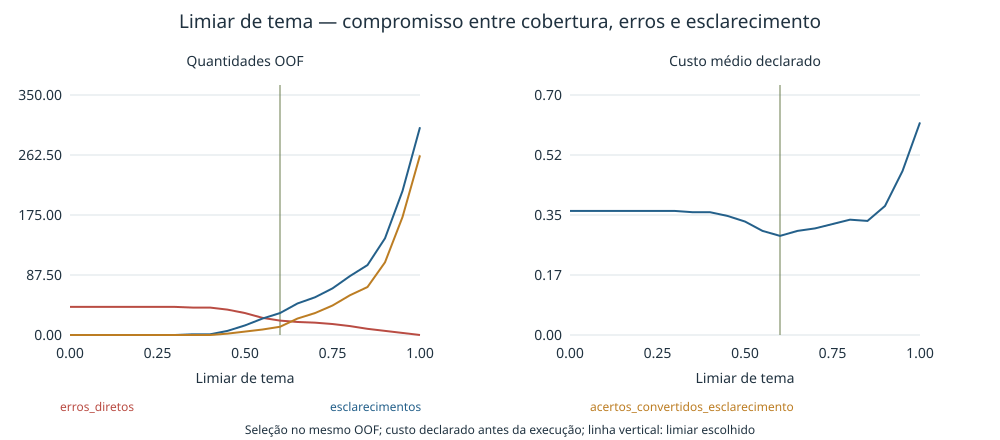

In [19]:
display(tabela09("limiares.csv"))
display(tabela09("limiares_sensibilidade.csv"))
display(SVG(data=resultado09["arquivos"]["limiar_compromisso.svg"]))
print("Critério:", meta09["criterio"])
print("Limitações:", meta09["limitacoes"])


## 14. Integração LangGraph sem LLM

A assinatura construir_grafo(config, clf_escopo, clf_tema) foi preservada. Os dois arquivos 08 continuam sendo os classificadores de produção. O classificador único é comparação experimental, sem substituição incompatível das classes de escopo/tema.

Os dez cenários fictícios foram fixados antes da seleção do limiar e não entram em dados científicos. As oito primeiras linhas têm intenção esperada; as duas últimas demonstram ambiguidade e múltiplas intenções sem rótulo único. Preservamos resultados errados e esclarecimentos: não se retocaram exemplos, modelos ou limiar para fazer o smoke test passar. Os testes contratuais com classificadores controlados cobrem todas as rotas; isso não prova generalização dos modelos reais.

Confiança não detecta toda ambiguidade. Pode haver erro com confiança alta, pergunta ambígua classificada como social ou mensagem composta atendida só na intenção dominante. A interface trabalha com uma intenção por mensagem; não há detector multilabel garantido.


In [20]:
integracao09 = tabela09("integracao_ficticios.csv")
display(integracao09)
assert integracao09["fonte_resposta"].eq("fixa").all()
assert integracao09["resposta"].str.len().gt(0).all()
print("Dez cenários com rota e resposta fixa; erros semânticos permanecem visíveis.")


Dez cenários com rota e resposta fixa; erros semânticos permanecem visíveis.


,tipo_esperado,texto_ficticio,rota,confianca_intencao,resposta,fonte_resposta,escopo
0,cardapio,"Olá, qual prato vai compor a refeição de quart...",valores,0.885929,"Estudantes de graduação, mestrado, doutorado e...",fixa,dominio
1,horarios,A que horas o restaurante universitário começa...,horarios,0.923589,"Em Campo Grande, de segunda a sexta: café da m...",fixa,dominio
2,valores,Sou estudante de graduação: qual preço cobram ...,valores,0.864535,"Estudantes de graduação, mestrado, doutorado e...",fixa,dominio
3,recarga_creditos,Queria entender como pago a refeição do RU: dá...,valores,0.682649,"Estudantes de graduação, mestrado, doutorado e...",fixa,dominio
4,cadastro,É minha primeira visita ao restaurante univers...,esclarecer,0.587510,Não tenho certeza se entendi. Sua dúvida é sob...,fixa,dominio
5,regras_uso,Posso almoçar no restaurante levando minha pró...,regras_uso,0.948851,"O RU atende estudantes de graduação, mestrado,...",fixa,dominio
6,chitchat,"Bom dia, assistente, obrigado pela atenção!",chitchat,0.000000,Por nada! Bom apetite!,fixa,chitchat
7,fora_dominio,Como faço a renovação de empréstimo na bibliot...,fora_dominio,0.000000,"Desculpe, só sei responder sobre o Restaurante...",fixa,fora_dominio
8,ambiguo_sem_rotulo_unico,Como eu consigo usar isso?,chitchat,0.000000,"Sou o Rango, assistente automático do RU, e po...",fixa,chitchat
9,multiplas_intencoes,Qual é o preço do jantar e o que vai ter para ...,valores,0.639756,"Estudantes de graduação, mestrado, doutorado e...",fixa,dominio


## 15. Análise científica desta execução

O texto a seguir é gerado das tabelas efetivamente calculadas. A leitura qualitativa também observou, no treino, confusão entre saudações e pedidos de cardápio, além de pedidos curtos de alimento rejeitados ou encaminhados para outro tema. Isso sugere dependência lexical e problemas de escopo, sem demonstrar causalidade. Não foi feita alteração da curadoria nem uso do teste para corrigir esses casos. A vantagem numérica de uma arquitetura não implica significância estatística.


In [21]:
display(Markdown(resultado09["arquivos"]["RESUMO_CIENTIFICO.md"]))


# A1, limiar e integração — resultados reais da Missão 09

Cinco folds externas comuns estratificadas nas oito classes; busca de C em três folds internas, calibração em três folds próprias. SVM linear calibrada e TF-IDF char_wb (2,5) em ambas as arquiteturas. O tema é ajustado somente nos rótulos originais de domínio do treino externo. Sem teste reservado.

## A1: desempenho ponta a ponta

```csv
arquitetura,f1_macro_media,f1_macro_desvio,accuracy_media,accuracy_desvio,f1_macro_oof,accuracy_oof,erros_oof,falsos_aceites_oof,falsas_recusas_oof,taxa_falso_aceite_oof,taxa_falsa_recusa_oof
cascata_cv_interna,0.8821050625944131,0.014005977819395238,0.889090909090909,0.010601730717900566,0.8825190070892993,0.889090909090909,61,20,13,0.08,0.043333333333333335
unico_cv_interna,0.8851152036523725,0.018913247406286998,0.890909090909091,0.019069251784911864,0.8854211136755381,0.8909090909090909,60,17,20,0.068,0.06666666666666667
```

Diferença de F1 macro médio (único − cascata): 0.003010. A diferença é pequena e as folds não são amostras independentes; não se afirma significância ou superioridade geral. A família/representação foi informada pela 08, portanto a busca interna de C não elimina todo o viés de seleção anterior.

O classificador único tem uma vetorização e aprende as oito classes conjuntamente. A cascata separa explicitamente o escopo e reduz o conjunto do tema, mas paga duas calibrações/vetorizações e pode bloquear perguntas cujo tema seria reconhecido. Os arquivos de produção 08 foram preservados: o único é comparação experimental, e a integração continua usando os dois classificadores exigidos pelo contrato.

## Propagação de erros

```csv
arquitetura,n_dominio,dominio_perdido_no_escopo,tema_correto_mas_bloqueado_pelo_escopo,dominio_passou_mas_tema_errou,n_nao_dominio,nao_dominio_encaminhado_ao_tema
cascata_cv_interna,300,13,11,22,250,20
cascata_referencia_08,300,16,14,22,250,19
```

## Custo observado

```csv
arquitetura,segundos_ajuste,ms_por_mensagem_batch,bytes_modelos_em_memoria,vocabularios_soma
cascata_cv_interna,1.2458157335961004,0.07040151458402925,609792.8,11841.2
unico_cv_interna,0.9195486081967829,0.036521665434437724,614408.4,7434.2
```

Tempos são observações locais, um job/thread, sem benchmark estatístico. A predição diagnóstica da cascata calcula tema para toda a validação para analisar propagação; não equivale à latência online, que pode pular o tema nas recusas. O tempo da cascata de referência registra só refits adicionais/reuso e não deve ser comparado com o ajuste completo das arquiteturas. Tamanhos são serializações em memória de modelos das folds, não novos arquivos de produção.

## Limiar operacional da cascata 08

Limiar de tema escolhido: 0.60. Critério pré-declarado: custo de falso aceite 5, intenção errada 3, esclarecimento 1, falsa recusa 2 e troca social/fora 1. São pesos internos, não uma exigência do professor nem utilidades validadas com usuários.

Sem limiar: 303 respostas de intenção, 41 erradas, precisão condicional 86.4686%. Com limiar: 271 respostas de intenção, 21 erradas, precisão condicional 92.2509%; 32 esclarecimentos, 20 erros evitados e 12 acertos convertidos. Custo total 199 → 159. F1 ponta a ponta no mesmo OOF: 0.878652 → 0.883098; esclarecimento não é acerto de intenção.

O limiar usa previsões OOF das configurações fixas 08, produzidas nas folds comuns desta missão; não mistura OOF de tema/escopo com divisões incompatíveis. A seleção e a descrição do limiar usam os mesmos OOF e são otimistas. Não há avaliação independente da política; famílias/autores podem atravessar folds. A sensibilidade dos pesos está em limiares_sensibilidade.csv, sem escolher pesos pelos resultados.

## Integração e limites semânticos

```csv
tipo_esperado,rota,confianca_intencao,fonte_resposta
cardapio,valores,0.885929109741886,fixa
horarios,horarios,0.9235888574672001,fixa
valores,valores,0.8645347871753708,fixa
recarga_creditos,valores,0.6826485616483978,fixa
cadastro,esclarecer,0.5875102439203995,fixa
regras_uso,regras_uso,0.9488506705437946,fixa
chitchat,chitchat,0.0,fixa
fora_dominio,fora_dominio,0.0,fixa
ambiguo_sem_rotulo_unico,chitchat,0.0,fixa
multiplas_intencoes,valores,0.6397561202183233,fixa
```

Todos os cenários são fictícios, fixados antes da seleção do limiar, sem entrar nos CSVs científicos. As respostas são fixas e não usam chave ou OpenRouter. Os testes contratuais com classificadores controlados cobrem seis intenções, social, fora e esclarecimento; eles não demonstram qualidade semântica dos modelos reais.

Os casos naturais permanecem no relatório inclusive quando falham. Limiar de confiança não é detector garantido de ambiguidade ou múltiplas intenções: uma pergunta ambígua pode ser classificada como social, e uma pergunta composta pode receber somente a intenção dominante. Erros confiantes de cardápio/pagamento também podem passar pelo limiar. Não se modificaram frases, pesos ou modelos para fazer estes exemplos passar.

Próxima etapa: revisão dos resultados pelo grupo e preparação autorizada do RAG. Nenhuma avaliação oficial ou verificação de entrega foi executada.


## 16. Integridade e reprodutibilidade da Missão 09

A execução é integralmente offline. O comando `.venv/bin/python -I -B scripts/aprofundar_classificadores.py --gravar` reproduz o A1, exporta as tabelas/figuras e atualiza somente roteamento.limiar_tema. A opção --emitir-json calcula/exporta em memória quando a escrita de processos é restrita; nesta sessão os artefatos textuais reais foram persistidos pelo editor permitido.

Os dados, modelos e resultados 08 e os três arquivos oficiais devem permanecer idênticos. A escolha e a integração foram assistidas por Codex; não se declara revisão humana do código, das métricas ou do limiar. Nenhum avaliador oficial, verificador ou OpenRouter foi executado.


In [22]:
assert referencias(raiz09) == meta09["referencias_08_e_dados"]
from chatbot.config import carregar_config
config09 = carregar_config(raiz09 / "grupo.yaml")
assert config09.limiar_tema == meta09["limiar_tema"]
print("Dados, modelos/resultados 08 e arquivos oficiais preservados.")
print("Limiar configurado:", config09.limiar_tema, "| Avaliação final NÃO executada.")


Dados, modelos/resultados 08 e arquivos oficiais preservados.
Limiar configurado: 0.6 | Avaliação final NÃO executada.
